# Recepción del estreno: reseñas positivas y negativas (4 al 13 de abril de 2025)

## ¿Qué queremos responder?

Queremos saber cómo recibieron *A Minecraft Movie* los dos grupos que opinan sobre una película: los **usuarios** (público general) y los **críticos** (periodistas y reseñistas). Nos interesan dos cosas:

1. Durante la primera semana del estreno, ¿cuántas reseñas fueron positivas, mixtas o negativas?
2. ¿Los críticos y el público opinaron parecido, o hubo diferencias?

## Criterios que seguimos

- **Ventana de análisis:** del 4 al 13 de abril de 2025. El estreno fue el 4 de abril, así que esta ventana muestra la reacción inmediata.
- **Fuente:** `data/raw/estreno_reviews.csv`, con reseñas de Metacritic. Los usuarios vienen de un PDF exportado y los críticos de un archivo que armó el equipo.
- **Clasificación de usuarios:** el puntaje va de 0 a 10. Entre 7 y 10 es **positiva**, entre 4 y 6 es **mixta** y entre 0 y 3 es **negativa**. Son los cortes que usa Metacritic.
- **Clasificación de críticos:** viene en el archivo como positiva, mixta o negativa, así que no la recalculamos.

## Por qué comparamos porcentajes y no promedios

Los usuarios puntúan de 0 a 10 y los críticos de 0 a 100, así que los promedios no se pueden comparar. Por eso usamos porcentajes, qué parte de las reseñas de cada grupo fue positiva, mixta o negativa.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/estreno_reviews.csv')
print('Reseñas:', df.shape)
df.head()

Reseñas: (200, 9)


,fuente,tipo,autor,medio,fecha_original,fecha,puntaje_original,clasificacion,texto
0,"Metacritic (críticos, archivo del equipo)",critico,New York Magazine (Vulture),New York Magazine (Vulture),5/4/2025,2025-04-05,80,Positiva,It feels like a small miracle that the resulti...
1,"Metacritic (críticos, archivo del equipo)",critico,The Observer (UK),The Observer (UK),5/4/2025,2025-04-05,20,Negativa,"Perhaps there’s an alternative out there, a sh..."
2,"Metacritic (críticos, archivo del equipo)",critico,Film Threat,Film Threat,4/4/2025,2025-04-04,20,Negativa,"A Minecraft Movie is not funny, exciting, or c..."
3,"Metacritic (críticos, archivo del equipo)",critico,Slashfilm,Slashfilm,5/4/2025,2025-04-05,70,Positiva,Hess and his army of screenwriters (only five ...
4,"Metacritic (críticos, archivo del equipo)",critico,Collider,Collider,4/4/2025,2025-04-04,50,Mixta,I do believe that there was a scenario where A...


## 1. Exploración inicial

Revisamos las columnas, sus tipos y los valores vacíos. La columna `medio` queda vacía en los usuarios, porque no tienen un medio asociado (es normal).

In [2]:
print(df.dtypes)
print()
print(df.isnull().sum())

fuente                str
tipo                  str
autor                 str
medio                 str
fecha_original        str
fecha                 str
puntaje_original    int64
clasificacion         str
texto                 str
dtype: object

fuente                0
tipo                  0
autor                 0
medio               189
fecha_original        0
fecha                 0
puntaje_original      0
clasificacion         0
texto                 0
dtype: int64


## 2. Limpieza

Limpiamos dos cosas. Primero, quitamos los espacios sobrantes en los nombres de los autores con `strip()`, para que dos nombres iguales no se cuenten como distintos. Segundo, buscamos reseñas repetidas por tipo, autor, fecha y puntaje. Si hay repetidas, las eliminamos para no contarlas dos veces.

Las fechas ya vienen en formato `AAAA-MM-DD`, así que no hace falta convertirlas. Por último, verificamos que el puntaje sea un número entero entre 0 y 10 para usuarios (o entre 0 y 80 en el caso de los críticos, que usan otra escala).

In [ ]:
# Quita los espacios al inicio y al final de cada nombre de autor
# Así "Juan " y "Juan" se cuentan como la misma persona
df['autor'] = [a.strip() for a in df.autor]

# Cuenta cuántas filas están repetidas del mismo tipo, autor, fecha y puntaje
# Si hay alguna, esa reseña aparece más de una vez en el archivo
print('Duplicados:', df.duplicated(['tipo', 'autor', 'fecha', 'puntaje_original']).sum())

# Elimina las repetidas y deja solo una copia de cada reseña
# reset_index vuelve a numerar las filas desde 0 para que no queden huecos
df = df.drop_duplicates(['tipo', 'autor', 'fecha', 'puntaje_original']).reset_index(drop=True)

# Muestra las reseñas limpias
print('Reseñas después de limpiar:', len(df))

Duplicados: 0
Reseñas después de limpiar: 200


**Tipos.** El puntaje tiene que ser numérico. Lo verificamos.

In [13]:
# Convierte la columna de puntajes a nros enteros
df['puntaje_original'] = df.puntaje_original.astype(int)

print('Puntaje más bajo:', df.puntaje_original.min())
print('Puntaje más alto:', df.puntaje_original.max())
print('Tipo de dato:', df.puntaje_original.dtype)

Puntaje más bajo: 0
Puntaje más alto: 80
Tipo de dato: int64


## 3. Clasificación en positiva, mixta y negativa

La columna `clasificacion` ya viene en el archivo, pero la verificamos para usuarios. Aplicamos la regla de los cortes del sitio a cada puntaje y comparamos el resultado con la clasificación del archivo. Si todas coinciden, la clasificación es confiable y podemos usarla con tranquilidad.

In [ ]:
# 1. Define la regla. Recibe un puntaje y devuelve una categoría
def clasificar_usuario(p):
    if p >= 7:
        return 'Positiva'
    elif p >= 4:
        return 'Mixta'
    else:
        return 'Negativa'

# 2. Se queda solo con las filas de usuarios, para no mezclar con los críticos
#    copy() crea una copia independiente, así podemos agregar columnas sin problemas
usuarios = df[df.tipo == 'usuario'].copy()

# 3. Aplica la regla a cada puntaje y guarda el resultado en una columna nueva llamada 'regla'
usuarios['regla'] = [clasificar_usuario(p) for p in usuarios.puntaje_original]

# 4. Compara fila por fila la columna 'regla' con la columna 'clasificacion' que ya traía el archivo
#    == revisa si son iguales Y all() dice True solo si todas las filas coinciden
print('Coinciden con la regla:', (usuarios.regla == usuarios.clasificacion).all())

Coinciden con la regla: True


## 4. Resultados generales: críticos vs. usuarios

En esta tabla contamos cuántas reseñas cayeron en cada clasificación y calculamos su porcentaje.

**Cómo leerla:** cada fila es una clasificación (positiva, mixta o negativa) y cada columna es un grupo. Las columnas `_n` muestran la cantidad de reseñas y las columnas `_%` muestran el porcentaje que representan dentro de su grupo. Por ejemplo, si los usuarios tienen 50,8 % en positiva, significa que de cada 100 reseñas de usuarios, unas 51 fueron positivas.

Hay 189 reseñas de usuarios, pero solo 11 de críticos. Con tan pocas reseñas de críticos, un solo cambio mueve mucho el porcentaje. Por eso sus números son una referencia y no una conclusión firme.

In [ ]:
# Define el orden de las clasificacion
columnas = ['Positiva', 'Mixta', 'Negativa']

# Cuenta cuántas reseñas de usuarios hay en cada clasificacion
conteo_usuarios = usuarios.clasificacion.value_counts()

# Calcula el porcentaje de cada clasificación dentro de los usuarios
# normalize=True devuelve proporciones (0,508 en vez de 50,8) y por eso se multiplica por 100 y se redondea a un decimal
pct_usuarios = (usuarios.clasificacion.value_counts(normalize=True) * 100).round(1)

# Separa las filas de críticos
criticos = df[df.tipo == 'critico']

# Cuenta y calcula los porcentajes de los críticos al igual que con los usuarios
conteo_criticos = criticos.clasificacion.value_counts()
pct_criticos = (criticos.clasificacion.value_counts(normalize=True) * 100).round(1)

# Junta los cuatro resultados en una tabla
# Las filas son Positiva, Mixta y Negativa. fillna(0) pone 0 donde no hay reseñas
resumen = pd.DataFrame({
    'usuarios_n': conteo_usuarios, 'usuarios_%': pct_usuarios,
    'criticos_n': conteo_criticos, 'criticos_%': pct_criticos
}).fillna(0)

# Mostramos la tabla
resumen

,usuarios_n,usuarios_%,criticos_n,criticos_%
clasificacion,,,,
Mixta,29,15.3,5,45.5
Negativa,64,33.9,4,36.4
Positiva,96,50.8,2,18.2


## 5. Evolución día a día

Esta parte mira solo a los usuarios, porque son el grupo con más reseñas. Agrupamos las reseñas por fecha y clasificación para ver si el entusiasmo se mantuvo durante la semana o fue bajando.

**Cómo leer el gráfico:** cada barra es un día. El verde son las positivas, el amarillo las mixtas y el rojo las negativas. La altura total de la barra muestra cuántas reseñas hubo ese día, así que también nos dice cuándo se concentró la conversación.

In [ ]:
# Agrupa por fecha y clasificacion. fill_value=0 pone 0 donde no hubo reseñas
por_dia = usuarios.groupby(['fecha', 'clasificacion']).size().unstack(fill_value=0)

# Agrega las columnas que falten con valor 0
for c in columnas:
    if c not in por_dia.columns:
        por_dia[c] = 0

# Ordena las columnas y suma el total de reseñas de cada dia
por_dia = por_dia[columnas]
por_dia['total'] = por_dia.sum(axis=1)

por_dia

clasificacion,Positiva,Mixta,Negativa,total
fecha,,,,
2025-04-04,17,2,13,32
2025-04-05,27,6,12,45
2025-04-06,15,1,10,26
2025-04-07,15,3,10,28
2025-04-08,10,5,3,18
2025-04-09,4,4,4,12
2025-04-10,4,1,2,7
2025-04-11,0,2,2,4
2025-04-12,4,3,5,12


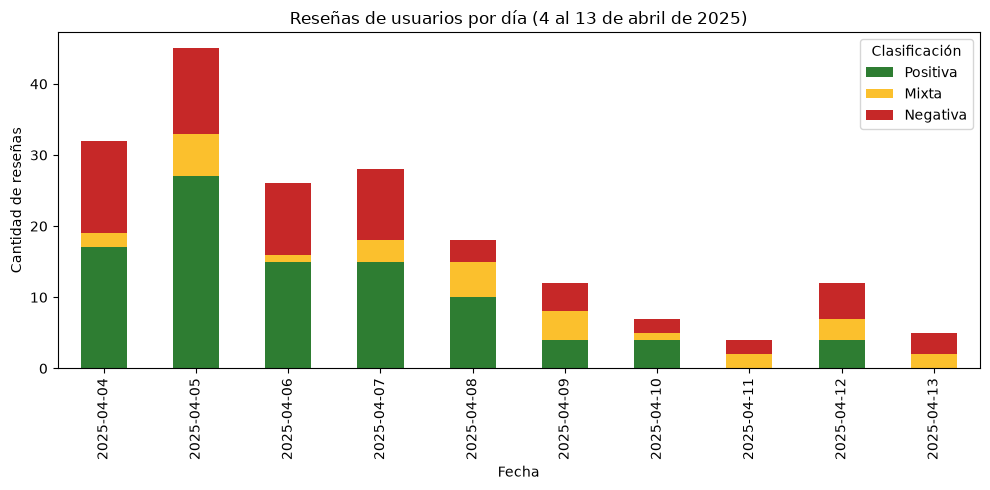

In [ ]:
# Dibuja una barra por dia apilando positivas, mixtas y negativas.
por_dia[columnas].plot(kind='bar', stacked=True, figsize=(10, 5),
                       color=['#2E7D32', '#FBC02D', '#C62828'])

# Colocamos título, nombres de los ejes y leyenda
plt.title('Reseñas de usuarios por día (4 al 13 de abril de 2025)')
plt.xlabel('Fecha')
plt.ylabel('Cantidad de reseñas')
plt.legend(title='Clasificación')

# Ajusta los márgenes para que no se corten los textos y muestre el gráfico
plt.tight_layout()
plt.show()

## 6. Comparación visual: críticos vs. usuarios

Este gráfico pone las dos columnas de porcentajes una al lado de la otra. Cada grupo de barras es una clasificación, y cada color es un grupo: azul oscuro para los críticos y azul claro para los usuarios.

Lo que buscamos es ver dónde se separan los grupos. Si las barras de un color son mucho más altas en una clasificación, ese grupo se inclinó hacia esa opinión.

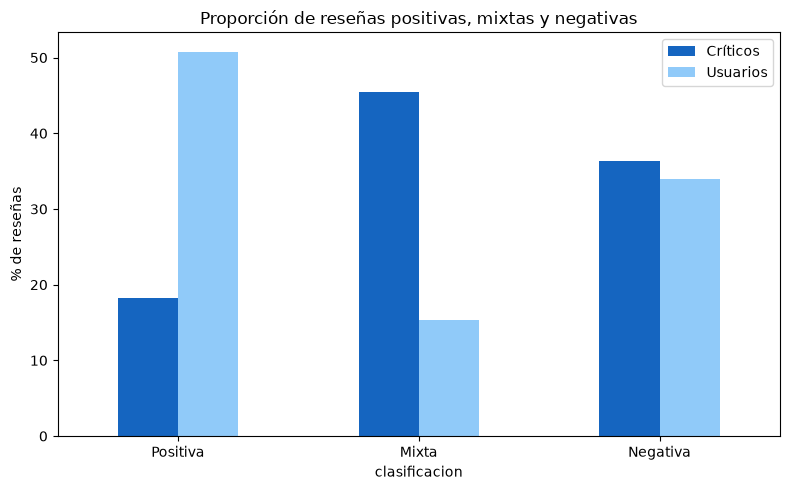

,Críticos,Usuarios
clasificacion,,
Positiva,18.2,50.8
Mixta,45.5,15.3
Negativa,36.4,33.9


In [ ]:
# Une los porcentajes de críticos y usuarios en una tabla
# reindex pone las filas en el orden de columnas
comp = pd.DataFrame({'Críticos': pct_criticos, 'Usuarios': pct_usuarios}).reindex(columnas).fillna(0)

# Dibuja dos barras por clasificación (una por grupo).
comp.plot(kind='bar', figsize=(8, 5), color=['#1565C0', '#90CAF9'])

# Colocamos título, nombre del eje y deja las etiquetas horizontales.
plt.title('Proporción de reseñas positivas, mixtas y negativas')
plt.ylabel('% de reseñas')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comp

## 7. Hallazgos

Cada hallazgo tiene tres partes: el **dato** (qué muestran los números), la **interpretación** (qué puede significar) y la **conclusión** (qué podemos afirmar con seguridad).

**1. El público fue mayoritariamente positivo.**
- **Dato:** el 50,8 % de las reseñas de usuarios fueron positivas, el 15,3 % mixtas y el 33,9 % negativas (189 reseñas).
- **Interpretación:** la mitad del público salió conforme con la película, pero una tercera parte no. No hubo una recepción unánime.
- **Conclusión:** la recepción inicial del público fue positiva, aunque con un grupo importante de descontentos.

**2. Los críticos fueron menos entusiastas que el público.**
- **Dato:** el 18,2 % de los críticos fue positivo, el 45,5 % mixto y el 36,4 % negativo (11 reseñas). La diferencia más grande está en las positivas: 32,6 puntos menos que los usuarios.
- **Interpretación:** los críticos no rechazaron la película, pero tampoco la celebraron. Muchos se quedaron en una valoración intermedia, mientras que el público tendió a los extremos (positivo o negativo).
- **Conclusión:** existe una diferencia de tono entre críticos y público. Con 11 reseñas, sin embargo, no podemos afirmarla con firmeza.

**3. El entusiasmo de los usuarios fue bajando con el correr de la semana.**
- **Dato:** las positivas fueron el 57 % los días 4 y 5 de abril (44 de 77 reseñas), y bajaron al 33 % los días 9 y 12 (8 de 24). Los días 11 y 13 no hubo ninguna positiva.
- **Interpretación:** la conversación más entusiasta se concentró en el fin de semana del estreno, cuando hubo más reseñas. Después del 8 de abril el volumen bajó y el tono se volvió más dividido.
- **Conclusión:** las tendencias posteriores al 8 de abril se basan en pocas reseñas por día, así que hay que tomarlas con cuidado.

## Limitaciones

- **Pocas reseñas de críticos.** Con 11, un cambio de una o dos reseñas mueve mucho los porcentajes.
- **Escalas distintas.** Usuarios (0–10) y críticos (0–100) no se pueden comparar en promedio, solo en proporciones.

## Qué significa en resumen

El público tuvo opiniones claras. La mayoría de sus reseñas fueron positivas o negativas. Los críticos, en cambio, escribieron sobre todo reseñas intermedias, que no son ni buenas ni malas del todo.

Como hay muy pocas reseñas de críticos, esta diferencia es una tendencia y no un resultado seguro.